# 00 — 数据审计（Data audit）

**项目：** 商品期货 calendar spread（MTH 9897, Project 7）  
**输入：** `data/raw/bloomberg_commodity_bulk_tickers_1986_2026.csv`  
**范围：** 只读审计。这里不保存任何 processed panel；`01_panel_build` 才负责建 panel 和保存。

Raw 文件是 24 个商品 × 4 个 generic nearby rank（M1–M4）× 4 个字段：
settlement price、volume、open interest、真实 contract code。

这个 notebook 回答四个问题：

1. 文件里有什么、缺什么？
2. Generic roll 到底怎么发生？
3. 哪些价格/成交量异常是真实的？
4. 在选择 universe threshold 之前，各商品/rank 的流动性大概是什么样？


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))


In [2]:
import pandas as pd

from src import qa, viz
from src.load import load_rank_panel

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)


## 1. 读入 raw 文件

Loader 会读 6 行 header，把 96 个 ticker group 拆开，解析真实 contract code，
最后返回一行一个 `date × commodity × rank` 的 long panel。


In [3]:
rank = load_rank_panel()
print(f"{rank.shape[0]:,} rows × {rank.shape[1]} columns")
rank[["date", "root", "rank", "contract_code", "settle"]].head()


1,013,664 rows × 23 columns


,date,root,rank,contract_code,settle
0,1986-01-02,BO,1,BOF86,21.62
1,1986-01-02,BO,2,BOH86,21.96
2,1986-01-02,BO,3,BOK86,22.20
3,1986-01-02,BO,4,BON86,22.65
4,1986-01-02,C,1,CH86,247.50


In [4]:
rank.groupby("sector")["root"].nunique().sort_values(ascending=False)


sector
Energy         5
Grains         4
Softs          4
Livestock      3
Metals         3
Oilseeds       3
Industrials    2
Name: root, dtype: int64

Panel 覆盖 24 个商品、7 个 sector。完全没有任何数据的日期（128 个美国市场假日）
会被丢掉；单个商品自己的缺口会保留为 missing value，不做 forward-fill。


## 2. Coverage（覆盖率）

`pct_missing` = 该商品/rank 在 union trading days 里没有 settlement 的比例。
大部分缺口来自晚上市、退市或 back month 太薄。


In [5]:
coverage = qa.coverage_summary(rank)
coverage.head(8)


,root,rank,first,last,n_valid,n_dates,pct_missing
0,BO,1,1986-01-02,2026-10-13,10274,10559,0.026991
1,BO,2,1986-01-02,2026-10-13,10281,10559,0.026328
2,BO,3,1986-01-02,2026-10-13,10281,10559,0.026328
3,BO,4,1986-01-02,2026-10-13,10281,10559,0.026328
4,C,1,1986-01-02,2026-10-13,10278,10559,0.026612
5,C,2,1986-01-02,2026-10-13,10280,10559,0.026423
6,C,3,1986-01-02,2026-10-13,10280,10559,0.026423
7,C,4,1986-01-02,2026-10-13,10279,10559,0.026518


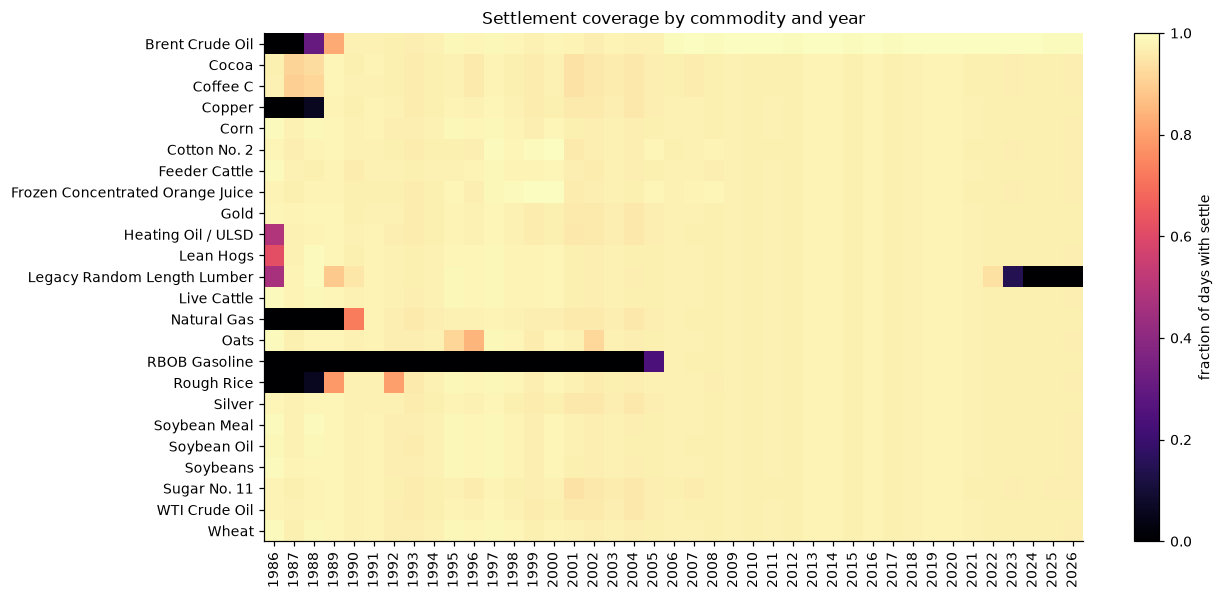

In [6]:
viz.plot_coverage_heatmap(rank);


按行看 commodity、按列看 year。空白不是价格 0，而是没有 coverage。
XB 2005 年才开始，LB 2023 年结束；CO/HG/RR/NG 也比 1986 晚。


## 3. Roll 机制：M1–M4 是 slot，不是合约

看 WTI 的第一次换月。1986-01-22 四个 rank 同时往前推一格：
新的 M1 是旧的 M2，新的 M2 是旧的 M3，以此类推。


In [7]:
cl = rank[(rank["root"] == "CL") & rank["date"].between("1986-01-19", "1986-01-24")]
cl.pivot_table(index="date", columns="rank", values=["contract_code", "settle"], aggfunc="first")


contract_code                      settle                     
rank                   1      2      3      4      1      2      3      4
date                                                                     
1986-01-20         CLG86  CLH86  CLJ86  CLK86  21.27  21.60  20.90  20.60
1986-01-21         CLG86  CLH86  CLJ86  CLK86  20.59  20.81  20.51  20.36
1986-01-22         CLH86  CLJ86  CLK86  CLM86  20.39  20.28  20.16  20.15
1986-01-23         CLH86  CLJ86  CLK86  CLM86  19.82  19.88  20.17  20.28
1986-01-24         CLH86  CLJ86  CLK86  CLM86  19.50  19.52  19.75  19.92

换月日直接算 M1 收益，会把 CLG86 和 CLH86 混在一起，这不是收益。
正确算法是用新合约自己前一天的价格（也就是旧 M2）：

`P_CLH86(t) / P_CLH86(t-1) - 1`，不是 `P_CLH86(t) / P_CLG86(t-1) - 1`。

`01_panel_build` 会实现这个 mapping，并把 naive vs correct 的差异展示出来。


In [8]:
roll = qa.assert_roll_sync(rank)
{key: roll[key] for key in ["n_full_roll_dates", "n_partial_rolls", "n_full_day_violations"]}


{'n_full_roll_dates': 6377, 'n_partial_rolls': 0, 'n_full_day_violations': 0}

## 4. 数据质量

最重要的 edge cases：contract code 缺失、volume/OI 缺失、stale price、以及唯一一个真实负价格。


In [9]:
qa.missing_summary(rank)


,rank,n,settle_missing,code_missing,volume_missing,oi_missing
0,1,253416,16537,152,37609,45279
1,2,253416,16294,146,35128,43464
2,3,253416,16605,142,37679,43606
3,4,253416,17076,143,46777,44285


In [10]:
qa.known_events_check(rank)


{'negative_rows': 1,
 'cl_2020_04_20_present': True,
 'cl_2020_04_20_settle': -37.63,
 'expected_settle': -37.63,
 'matches_expected': True}

In [11]:
rank.loc[rank["negative_price"], ["date", "root", "rank", "contract_code", "settle"]]


,date,root,rank,contract_code,settle
852108,2020-04-20,CL,1,CLK20,-37.63


In [12]:
qa.stale_summary(rank).sort_values("max_stale_run", ascending=False).head(8)


,root,rank,stale_pct,max_stale_run
67,O,4,0.085709,14
71,RR,4,0.066862,13
19,CO,4,0.011270,8
51,LB,4,0.038735,7
69,RR,2,0.036462,6
18,CO,3,0.010134,5
70,RR,3,0.046974,5
65,O,2,0.047164,5


- 583 行有 settlement 但没有 contract code；主要是假日/数据中断（例如 2001-09-11），无法对齐合约。
- Volume/OI 在 1986–1990 缺失较多；missing 不能当成 0。
- CL 2020-04-20 结算价 **−37.63**，是真实值；保留并 flag。
- M1 的 stale run 很短（最长 4 个 session）；部分 M4 合约会更长。


## 5. 流动性诊断（先不选 threshold）

对每条腿算 trailing 252 个 session 的 median volume/OI，并定义
`pair_liquidity = min(near, far)`。下面只是诊断；还没有应用任何 universe filter。


In [13]:
from src.panel import build_all, liquidity_summary

panels = build_all(rank)
universe = panels["universe"]
liquidity_summary(universe)


,threshold,pair_days,pass_volume_days,pass_oi_days,roots_pass_volume,roots_pass_oi
0,1000,236186,127944,180736,20,24
1,5000,236186,69301,151137,19,21
2,10000,236186,45043,125989,13,20
3,20000,236186,27121,91569,12,20


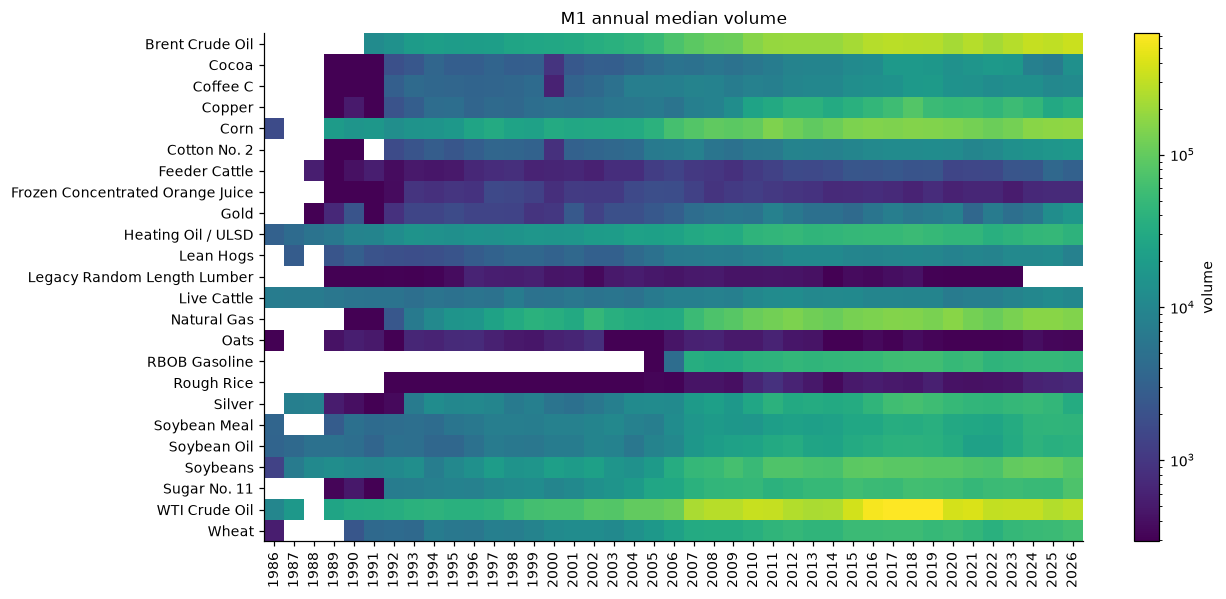

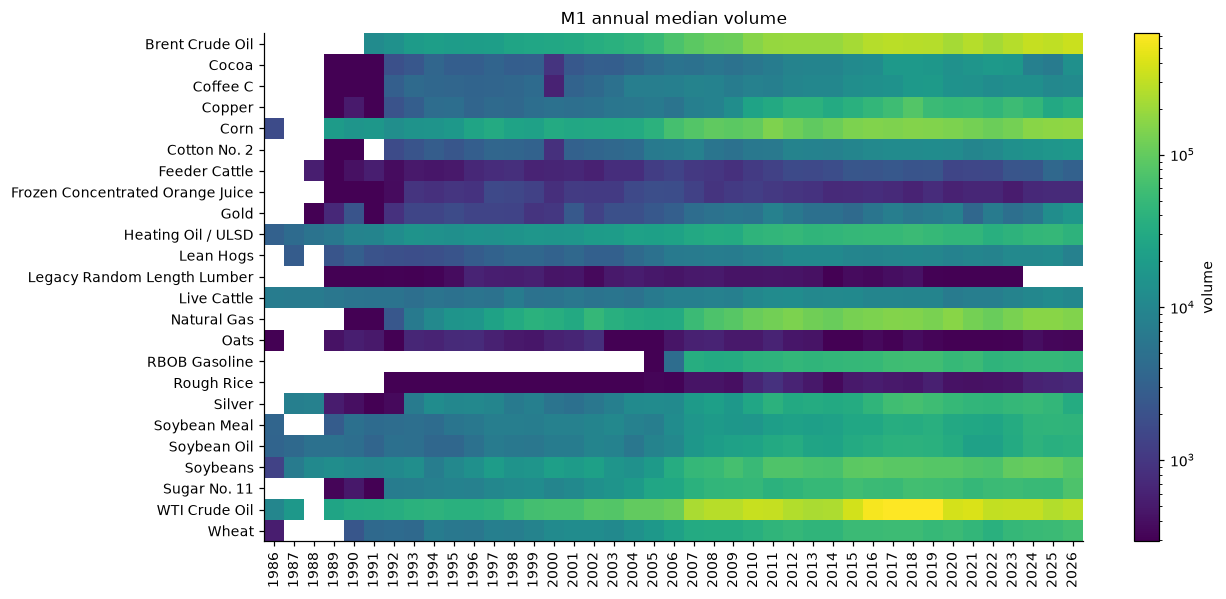

In [14]:
viz.plot_liquidity_heatmap(rank, rank=1, value="volume")


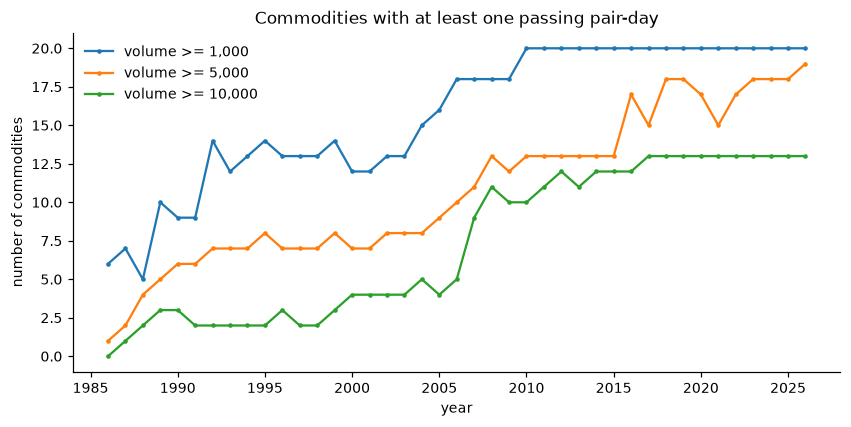

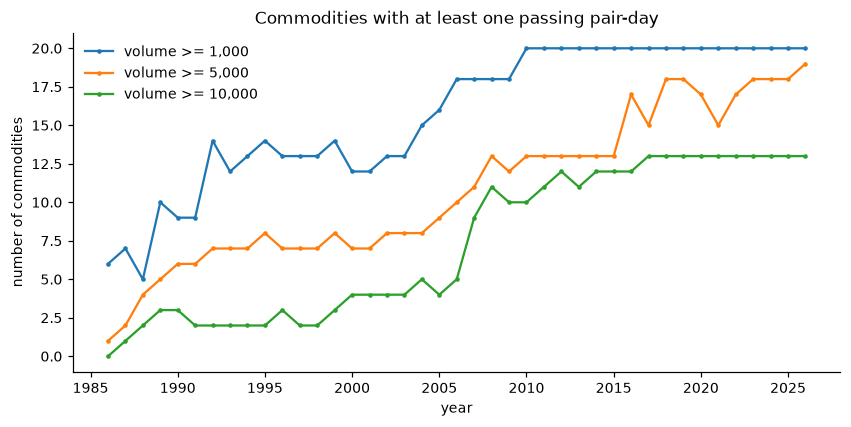

In [15]:
viz.plot_universe_counts(universe)


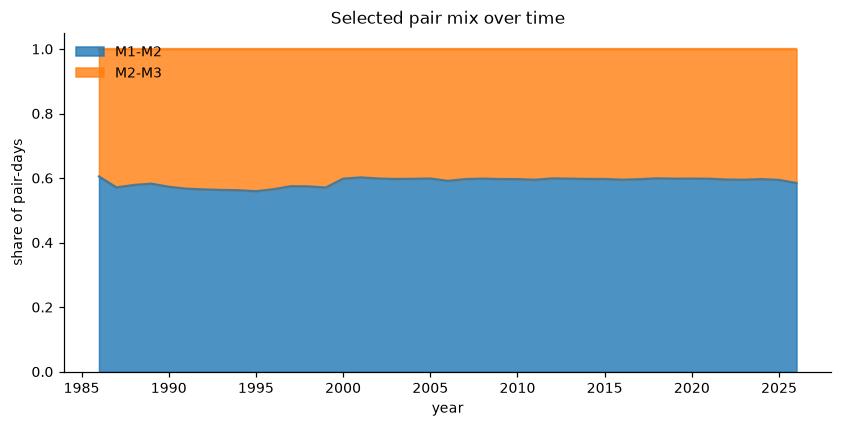

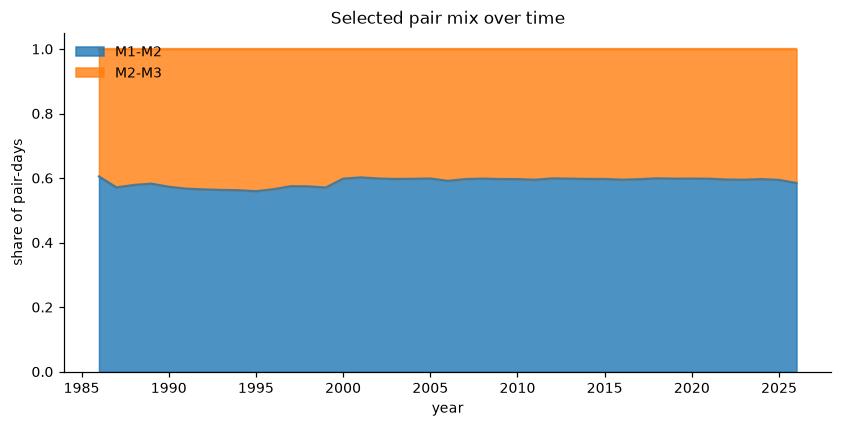

In [16]:
viz.plot_pair_mix(panels["pairs"])


5,000 手 trailing median 近年大约剩 19 个商品；M2–M3 明显比 M1–M2 薄。
Gold 是一个很好的 edge case：临近换月时 M1 可能比 M2 还不活跃。
最终 threshold 是研究选择，不是数据清洗规则；看完这些图再定。


## 6. Takeaways

- 24 个商品、96 条 generic series、10,640 个 weekday rows；6,735 张真实合约。
- 每个 full-coverage roll date，四个 rank 都一起换；clean panel 里没有 partial queue。
- 跨 roll 的 generic price 差分不是收益；contract-level mapping 是整个项目不可跳过的一步。
- Contract code 缺失很少，集中在假日/中断；volume/OI 缺失在早期很常见，不能当 0。
- CL 2020-04-20 是真实负价格；那一天的 log spread 无定义，dollar spread 仍然有定义。
- 流动性差异很大；universe threshold 要看完 pair-level 诊断再定。

**下一步：** `01_panel_build.ipynb` 建 panel 并保存。
